# Income and Poverty — Measuring Inequality with ACS Data

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-Year (pinned)

This notebook uses **real data only**. There is no synthetic generator and no fallback
path anywhere in it. If the Census API cannot be reached, or a key is absent, or a value
falls outside its stated plausible range, the notebook **stops**. It does not substitute
a number so that the cells below can keep running.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*


## Learning Objectives

By the end of this notebook you will be able to:

1. **Retrieve** household income, poverty and educational attainment estimates from the
   Census ACS API, with the vintage pinned and the provenance of every column recorded.
2. **Recognise** the two failure modes that silently corrupt public-data pipelines: a
   success status carrying an error page, and jam values that look like numbers.
3. **Construct** a Lorenz curve and compute a Gini coefficient from published income
   brackets, and state the assumptions that choice requires.
4. **Validate** your computed Gini against the Census's own published index — an external
   check that tells you whether your pipeline is right, not merely self-consistent.
5. **Distinguish** a descriptive association from a causal claim, and report an estimate
   with the uncertainty that a sample of 52 geographies actually supports.


## Prerequisites

**Knowledge.** Descriptive statistics; ordinary least squares and how to read a
confidence interval; what a survey estimate is and why it has a margin of error.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>,
placed in `~/.krl/secrets.env` as `CENSUS_API_KEY=...`. The key is read at runtime and is
never printed or written into this notebook's output.

**Packages.** `pandas`, `numpy`, `statsmodels`, `matplotlib`, `requests`, and the local
`krl_tutorials_data` package.

**Prior notebooks.** None. This is the foundational notebook of the series.


## Data Provenance

| Variable | Published label (verbatim) | Role |
|---|---|---|
| `B19013_001E` | Estimate!!Median household income in the past 12 months | context |
| `B19083_001E` | Estimate!!Gini Index | **external validation target** |
| `B17001_001E` | Estimate!!Total: (poverty universe) | poverty denominator |
| `B17001_002E` | Estimate!!Total:!!Income in the past 12 months below poverty level | poverty numerator |
| `B15003_001E` | Estimate!!Total: — universe: **population 25 years and over** | education denominator |
| `B15003_022E`–`B15003_025E` | Bachelor's / Master's / Professional / Doctorate | education numerator |
| `B19001_002E`–`B19001_017E` | Household income bracket counts | Lorenz / Gini input |

> **A denominator note that matters.** `B15003` has the universe *population 25 years and
> over*, so its correct denominator is `B15003_001E` — **not** `B01003_001E` (total
> population, all ages). Dividing by total population understates educational attainment
> by roughly the share of the population under 25. An audit of the previous version of
> this corpus found exactly that error, alongside a `uninsured_rate` built from
> `B27001_005E` — *males under 6 years with no health insurance* — which produced a
> national rate of 0.16% against a true value near 9%.


In [1]:
"""Configuration. Every analytic choice that follows is named here, not inferred."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Resolve the repository root by walking up to the package, so the
# notebook runs from any working directory.
_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / 'src' / 'krl_tutorials_data').is_dir():
        sys.path.insert(0, str(_cand / "src"))
        break
else:
    raise SystemExit('Could not locate krl_tutorials_data from ' + str(_here))

from krl_tutorials_data.sources import fetch_acs, DataAccessError
from krl_tutorials_data.inequality import (
    ACS_B19001_BRACKETS, lorenz_curve, gini_from_lorenz, BracketScheme,
)
from krl_tutorials_data.uncertainty import Estimate, proportion_moe, difference_is_significant

# --- Analytic specification -------------------------------------------------
# The target is NAMED. It is never inferred from column order: doing so is how
# the previous version of this notebook came to regress a constant `year`
# column and report R-squared = 1.000.
TARGET_COLUMN: str = "poverty_rate"
PREDICTOR_COLUMNS: tuple[str, ...] = ("bachelors_or_higher_share", "log_median_income")
UNIT_OF_ANALYSIS: str = "state (50 states + DC + Puerto Rico)"
ACS_VINTAGE: int = 2023
ALPHA: float = 0.05

pd.set_option("display.width", 110)
pd.set_option("display.max_columns", 24)
plt.rcParams["figure.dpi"] = 110

print(f"Target            : {TARGET_COLUMN}")
print(f"Predictors        : {', '.join(PREDICTOR_COLUMNS)}")
print(f"Unit of analysis  : {UNIT_OF_ANALYSIS}")
print(f"ACS vintage       : {ACS_VINTAGE} 5-Year (pinned)")

Target            : poverty_rate
Predictors        : bachelors_or_higher_share, log_median_income
Unit of analysis  : state (50 states + DC + Puerto Rico)
ACS vintage       : 2023 5-Year (pinned)


### Retrieving the data

Two failure modes are guarded explicitly, because both are silent:

**The success-status trap.** `api.census.gov` answers a request with a missing or
rejected key using **`HTTP 200` and an HTML page**. Code that branches on
`response.status_code == 200` accepts that page as data. The client below validates
content type and body shape, not the status line.

**Jam values.** ACS encodes suppressed or unavailable estimates as large negative
integers such as `-666666666`. Treated as numbers they destroy any mean they touch. The
client converts them to missing *before* any arithmetic.


In [2]:
BRACKETS = {f"B19001_{i:03d}E": f"Households: bracket {i-1}" for i in range(2, 18)}

VARIABLES = {
    "B19013_001E": "Estimate!!Median household income in the past 12 months",
    "B19083_001E": "Estimate!!Gini Index",
    "B17001_001E": "Estimate!!Total: (poverty status universe)",
    "B17001_002E": "Estimate!!Income in the past 12 months below poverty level",
    # Margins of error for the poverty rate. D01 previously listed "survey
    # uncertainty is not propagated" as its first limitation; these close it.
    "B17001_001M": "Margin of Error!!Total: (poverty status universe)",
    "B17001_002M": "Margin of Error!!Below poverty level",
    "B15003_001E": "Estimate!!Total: (population 25 years and over)",
    "B15003_022E": "Estimate!!Bachelor's degree",
    "B15003_023E": "Estimate!!Master's degree",
    "B15003_024E": "Estimate!!Professional school degree",
    "B15003_025E": "Estimate!!Doctorate degree",
    **BRACKETS,
}

# Stated plausible ranges. These are documentation as much as validation: they
# record what the analyst expected before seeing the data. A violation stops the
# notebook. Widening a bound to make a run pass is a methodological failure.
PLAUSIBLE = {
    "B19013_001E": (20_000, 160_000),   # median household income, dollars
    "B19083_001E": (0.30, 0.60),        # Gini index, published
}

try:
    raw, provenance = fetch_acs(
        year=ACS_VINTAGE,
        variables=VARIABLES,
        geography="state:*",
        plausible=PLAUSIBLE,
    )
except DataAccessError as exc:
    # Surface the cause BEFORE raising. A bare SystemExit is rendered by IPython
    # as a single line, which hides exactly the diagnostic a reader needs.
    print("HALTED — real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nThis notebook has no synthetic fallback by design: substituting a "
          "value here is what produced the defects the rebuild exists to fix.")
    raise

print(provenance.render())

Source      : U.S. Census Bureau - American Community Survey (acs/acs5)
Vintage     : 2023  (pinned)
Endpoint    : https://api.census.gov/data/2023/acs/acs5
Retrieved   : 2026-09-13T18:49:27+00:00
Shape       : 52 rows x 29 cols
Payload hash: 4c150c4790298c8e...
Data mode   : EMPIRICAL
Variables   :
              B19013_001E      Estimate!!Median household income in the past 12 months
              B19083_001E      Estimate!!Gini Index
              B17001_001E      Estimate!!Total: (poverty status universe)
              B17001_002E      Estimate!!Income in the past 12 months below poverty level
              B17001_001M      Margin of Error!!Total: (poverty status universe)
              B17001_002M      Margin of Error!!Below poverty level
              B15003_001E      Estimate!!Total: (population 25 years and over)
              B15003_022E      Estimate!!Bachelor's degree
              B15003_023E      Estimate!!Master's degree
              B15003_024E      Estimate!!Professiona

In [3]:
"""Derive the analysis frame. Every construct states its numerator and denominator."""
df = pd.DataFrame({
    "state": raw["NAME"],
    "median_household_income": raw["B19013_001E"],
    "gini_published": raw["B19083_001E"],
})

# Poverty rate: persons below poverty / persons for whom poverty status is determined.
df["poverty_rate"] = 100.0 * raw["B17001_002E"] / raw["B17001_001E"]

# Carry the published margin of error through the derived percentage, using the
# Census proportion formula (the numerator is a subset of the denominator).
df["poverty_rate_moe"] = [
    100.0 * proportion_moe(
        Estimate(float(r["B17001_002E"]), float(r["B17001_002M"])),
        Estimate(float(r["B17001_001E"]), float(r["B17001_001M"])),
    )
    for _, r in raw.iterrows()
]

# Educational attainment: bachelor's or higher, over the population 25 and over.
attained = raw[["B15003_022E", "B15003_023E", "B15003_024E", "B15003_025E"]].sum(axis=1)
df["bachelors_or_higher_share"] = 100.0 * attained / raw["B15003_001E"]

df["log_median_income"] = np.log(df["median_household_income"])

# --- Invariants. Each one rejects a defect found in the audited corpus. -----
assert df[TARGET_COLUMN].notna().all(), "Target contains missing values after construction."
assert df[TARGET_COLUMN].var() > 0, (
    "Target is constant. A zero-variance target yields a meaningless R-squared "
    "(the audited notebook reported 1.000 for exactly this reason)."
)
assert TARGET_COLUMN not in PREDICTOR_COLUMNS, "Target leaked into the predictor set."
for col in PREDICTOR_COLUMNS:
    assert df[col].notna().all(), f"Predictor {col} contains missing values."
    assert df[col].var() > 0, f"Predictor {col} is constant."

print(f"Rows: {len(df)}  ({UNIT_OF_ANALYSIS})")
print(f"Target `{TARGET_COLUMN}` variance: {df[TARGET_COLUMN].var():.4f}  (must exceed 0)")
print()
print(df[["state", "median_household_income", "poverty_rate",
          "bachelors_or_higher_share", "gini_published"]].head(8).to_string(index=False))

Rows: 52  (state (50 states + DC + Puerto Rico))
Target `poverty_rate` variance: 23.2734  (must exceed 0)

      state  median_household_income  poverty_rate  bachelors_or_higher_share  gini_published
    Alabama                  62027.0     15.632797                  27.755139          0.4783
     Alaska                  89336.0     10.182461                  31.242276          0.4333
    Arizona                  76872.0     12.759948                  32.610332          0.4624
   Arkansas                  58773.0     16.021200                  25.111375          0.4807
 California                  96334.0     11.966430                  36.503058          0.4887
   Colorado                  92470.0      9.383137                  44.727988          0.4576
Connecticut                  93760.0     10.026457                  41.944914          0.4984
   Delaware                  82855.0     10.725554                  35.277475          0.4495


In [4]:
"""What the margins do to a naive reading of the target."""
print("Poverty rate margins of error (90% confidence):")
print(f"  median {df['poverty_rate_moe'].median():.3f} pp, "
      f"max {df['poverty_rate_moe'].max():.3f} pp "
      f"({df.loc[df['poverty_rate_moe'].idxmax(), 'state']})")
print()

ranked = df.sort_values("poverty_rate", ascending=False).reset_index(drop=True)
est = {r["state"]: Estimate(r["poverty_rate"], r["poverty_rate_moe"])
       for _, r in ranked.iterrows()}
n_adj = len(ranked) - 1
n_sig_adj = sum(
    difference_is_significant(est[ranked.iloc[i]["state"]],
                              est[ranked.iloc[i + 1]["state"]])[0]
    for i in range(n_adj)
)
print(f"Adjacent-rank comparisons distinguishable at 90%: {n_sig_adj} of {n_adj} "
      f"({n_sig_adj / n_adj:.0%}).")
print("A ranked table of state poverty rates asserts an ordering the survey does")
print("not resolve at every step. D03 develops this properly.")
print()
print(ranked.head(5)[["state", "poverty_rate", "poverty_rate_moe"]].to_string(
    index=False, float_format=lambda v: f"{v:,.3f}"))

Poverty rate margins of error (90% confidence):
  median 0.223 pp, max 0.695 pp (District of Columbia)

Adjacent-rank comparisons distinguishable at 90%: 14 of 51 (27%).
A ranked table of state poverty rates asserts an ordering the survey does
not resolve at every step. D03 develops this properly.

        state  poverty_rate  poverty_rate_moe
  Puerto Rico        41.553             0.361
  Mississippi        19.065             0.367
    Louisiana        18.884             0.328
   New Mexico        18.101             0.377
West Virginia        16.641             0.358


## Inequality: building a Lorenz curve from published brackets

The Lorenz curve plots the cumulative share of income held by the poorest *p* share of
households. Perfect equality is the 45° diagonal; the Gini coefficient is twice the area
between the diagonal and the curve.

Computing it from `B19001` requires two assumptions that must be stated, because both
move the answer:

1. **Within-bracket uniformity.** Each closed bracket is represented by its midpoint.
   Income is right-skewed *inside* brackets as well as between them, so this biases the
   Gini slightly downward.
2. **The open top bracket.** `$200,000 or more` has no upper bound, so its mean must be
   assumed. The sensitivity of the result to that assumption is reported below rather
   than hidden.


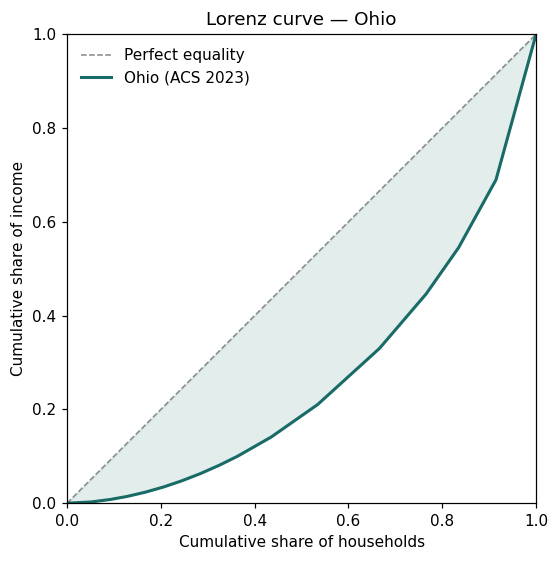

Ohio: computed Gini = 0.4624, Census published Gini = 0.4674


In [5]:
"""Compute the Lorenz curve and Gini for one state, then for all of them."""
bracket_cols = list(BRACKETS)

def state_gini(row: pd.Series, scheme: BracketScheme = ACS_B19001_BRACKETS) -> float:
    counts = row[bracket_cols].to_numpy(dtype=float)
    pop, inc = lorenz_curve(counts, scheme.midpoints())
    return gini_from_lorenz(pop, inc)

df["gini_computed"] = raw.apply(state_gini, axis=1)

example = "Ohio" if (raw["NAME"] == "Ohio").any() else raw["NAME"].iloc[0]
row = raw.loc[raw["NAME"] == example].iloc[0]
pop, inc = lorenz_curve(row[bracket_cols].to_numpy(dtype=float), ACS_B19001_BRACKETS.midpoints())

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#888", label="Perfect equality")
ax.plot(pop, inc, linewidth=2, color="#186b66", label=f"{example} (ACS {ACS_VINTAGE})")
ax.fill_between(pop, inc, pop, alpha=0.12, color="#186b66")
ax.set_xlabel("Cumulative share of households")
ax.set_ylabel("Cumulative share of income")
ax.set_title(f"Lorenz curve — {example}")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

print(f"{example}: computed Gini = {gini_from_lorenz(pop, inc):.4f}, "
      f"Census published Gini = {row['B19083_001E']:.4f}")

### The external validation step

This is the part of the notebook that distinguishes a correct pipeline from a merely
self-consistent one. The Census publishes its own Gini index (`B19083`) computed from
household microdata. Our figure comes from 16 published brackets and two stated
assumptions. The two should agree closely but **not exactly** — and the direction of the
disagreement is predictable from the assumptions above.

If the computed values did *not* track the published ones, the correct conclusion would
be that the pipeline is wrong — not that a new inequality measure had been discovered.


In [6]:
"""Validate the computed Gini against the Census's own published index."""
comparison = df[["state", "gini_computed", "gini_published"]].copy()
comparison["difference"] = comparison["gini_computed"] - comparison["gini_published"]

corr = comparison["gini_computed"].corr(comparison["gini_published"])
mean_abs_diff = comparison["difference"].abs().mean()
mean_signed_diff = comparison["difference"].mean()

# The verdict is DERIVED from the computed agreement, never asserted.
AGREEMENT_TOLERANCE = 0.05
within_tolerance = int((comparison["difference"].abs() <= AGREEMENT_TOLERANCE).sum())
verdict = "consistent" if corr > 0.80 and mean_abs_diff < AGREEMENT_TOLERANCE else "INCONSISTENT"

print("VALIDATION AGAINST PUBLISHED CENSUS GINI (B19083)")
print("=" * 62)
print(f"  Pearson correlation, computed vs published : {corr:.4f}")
print(f"  Mean absolute difference                   : {mean_abs_diff:.4f}")
print(f"  Mean signed difference                     : {mean_signed_diff:+.4f}")
print(f"  Geographies within +/-{AGREEMENT_TOLERANCE}                  : {within_tolerance} of {len(comparison)}")
print(f"  Pipeline verdict                           : {verdict}")
print()
print(comparison.reindex(comparison["difference"].abs().sort_values(ascending=False).index)
      .head(5).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

if verdict != "consistent":
    raise AssertionError(
        "Computed Gini does not track the published index. Stop and fix the "
        "pipeline before interpreting anything below."
    )

VALIDATION AGAINST PUBLISHED CENSUS GINI (B19083)
  Pearson correlation, computed vs published : 0.8216
  Mean absolute difference                   : 0.0117
  Mean signed difference                     : -0.0114
  Geographies within +/-0.05                  : 51 of 52
  Pipeline verdict                           : consistent

               state  gini_computed  gini_published  difference
District of Columbia         0.4549          0.5144     -0.0595
         Connecticut         0.4565          0.4984     -0.0419
            New York         0.4766          0.5152     -0.0386
          California         0.4536          0.4887     -0.0351
       Massachusetts         0.4527          0.4877     -0.0350


In [7]:
"""How much does the open-top-bracket assumption move the answer?"""
sensitivity = []
for top_mean in (250_000, 300_000, 350_000, 450_000, 600_000):
    scheme = BracketScheme(
        edges=ACS_B19001_BRACKETS.edges, top_mean=float(top_mean),
        top_mean_basis="sensitivity sweep",
    )
    g = raw.apply(lambda r: state_gini(r, scheme), axis=1)
    sensitivity.append({
        "assumed_top_mean": top_mean,
        "mean_gini": g.mean(),
        "mean_gap_vs_published": (g - df["gini_published"]).mean(),
    })

sens = pd.DataFrame(sensitivity)
print("SENSITIVITY TO THE OPEN TOP-BRACKET ASSUMPTION")
print(sens.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))
print()
print(f"Range of mean Gini across the sweep: "
      f"{sens['mean_gini'].min():.4f} to {sens['mean_gini'].max():.4f} "
      f"(spread {sens['mean_gini'].max() - sens['mean_gini'].min():.4f})")
print(ACS_B19001_BRACKETS.top_mean_basis)

SENSITIVITY TO THE OPEN TOP-BRACKET ASSUMPTION
 assumed_top_mean  mean_gini  mean_gap_vs_published
           250000     0.4094                -0.0589
           300000     0.4345                -0.0338
           350000     0.4569                -0.0114
           450000     0.4955                 0.0272
           600000     0.5415                 0.0732

Range of mean Gini across the sweep: 0.4094 to 0.5415 (spread 0.1321)
The top bracket ($200,000+) is open-ended, so its mean must be assumed. 350,000 is used as a documented placeholder; the notebook reports the sensitivity of the Gini to this choice rather than hiding it.


## Association, and what it is not

The model below asks a **descriptive** question: across states, how does the poverty rate
co-vary with educational attainment and median income?

It is **not** a causal estimate, and no part of this notebook licenses a causal reading.
There is no treatment, no identification strategy, no adjustment set and no refutation
test. States are not randomly assigned their education levels; anything that raises
attainment and lowers poverty simultaneously — industrial composition, migration, cost of
living, historical policy — is unmodelled and will load onto these coefficients.

Two further constraints on interpretation:

- **n = 52.** With two predictors this supports a coefficient and an interval, not a
  precise one. Effects smaller than roughly a percentage point will not be distinguishable.
- **Ecological inference.** These are state aggregates. A relationship between state
  averages does not license a claim about individuals — the ecological fallacy.


### Before you read those coefficients: a specification check

A coefficient is a statement about a *model*, not about the world. Below, the same
education variable is fitted three ways. Its sign changes depending on what else is in
the equation — which is why a single table of coefficients, reported without this check,
is how "more education is associated with more poverty" enters a slide deck.


In [8]:
"""Specification sensitivity and leverage. Run this BEFORE interpreting any coefficient."""
corr_xx = df[list(PREDICTOR_COLUMNS)].corr().iloc[0, 1]
vif = 1.0 / (1.0 - corr_xx ** 2)

print(f"corr({PREDICTOR_COLUMNS[0]}, {PREDICTOR_COLUMNS[1]}) = {corr_xx:+.4f}")
print(f"Variance inflation factor                = {vif:.2f}")
print()

specs = {
    "education alone": ["bachelors_or_higher_share"],
    "income alone": ["log_median_income"],
    "both (reported model)": list(PREDICTOR_COLUMNS),
}
rows = []
for label, cols in specs.items():
    m = sm.OLS(df[TARGET_COLUMN], sm.add_constant(df[cols])).fit(cov_type="HC3")
    rows.append({
        "specification": label,
        "r_squared": m.rsquared,
        "education_coef": m.params.get("bachelors_or_higher_share", float("nan")),
        "education_p": m.pvalues.get("bachelors_or_higher_share", float("nan")),
    })
spec_table = pd.DataFrame(rows)
print(spec_table.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))
print()

alone = spec_table.loc[spec_table.specification == "education alone", "education_coef"].iloc[0]
joint = spec_table.loc[spec_table.specification == "both (reported model)", "education_coef"].iloc[0]
sign_flipped = (alone < 0) != (joint < 0)
print(f"Education coefficient sign changes between specifications: {sign_flipped}")
if sign_flipped:
    print("  This is a suppression effect. Conditioning on income changes what the")
    print("  education coefficient means: it becomes the association between education")
    print("  and poverty AMONG STATES WITH THE SAME MEDIAN INCOME. It is not evidence")
    print("  about the effect of education, and the unconditional association has the")
    print("  opposite sign.")

# Leverage: units whose predictor values sit far from the rest of the sample.
z = (df[list(PREDICTOR_COLUMNS)] - df[list(PREDICTOR_COLUMNS)].mean()) / df[list(PREDICTOR_COLUMNS)].std()
df["_max_abs_z"] = z.abs().max(axis=1)
outliers = df.nlargest(3, "_max_abs_z")[["state", *PREDICTOR_COLUMNS, "_max_abs_z"]]
print()
print("Highest-leverage units (largest standardised predictor value):")
print(outliers.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))
# Render the comment on leverage FROM the table, rather than asserting which unit
# leads. Written as prose, this sentence drifted: it named the District of
# Columbia while Puerto Rico in fact carries the larger standardised deviation.
top = outliers.iloc[0]
print()
print(f"Highest-leverage unit: {top['state']} "
      f"({top['_max_abs_z']:.2f} SD from the sample mean on at least one predictor).")
print("Neither the District of Columbia nor Puerto Rico is a state. Both are reported")
print("alongside states by `geography=\"state:*\"`, and both sit far from the rest of")
print("the sample — DC on education, Puerto Rico on income. Exercise 6 asks you to")
print("refit without each and check whether any conclusion survives.")

corr(bachelors_or_higher_share, log_median_income) = +0.6681
Variance inflation factor                = 1.81

        specification  r_squared  education_coef  education_p
      education alone     0.1319         -0.2596       0.1984
         income alone     0.7735             NaN          NaN
both (reported model)     0.8645          0.2897       0.0607

Education coefficient sign changes between specifications: True
  This is a suppression effect. Conditioning on income changes what the
  education coefficient means: it becomes the association between education
  and poverty AMONG STATES WITH THE SAME MEDIAN INCOME. It is not evidence
  about the effect of education, and the unconditional association has the
  opposite sign.

Highest-leverage units (largest standardised predictor value):
               state  bachelors_or_higher_share  log_median_income  _max_abs_z
         Puerto Rico                      29.13              10.13        4.88
District of Columbia                    

In [9]:
"""OLS with intervals. Every reported claim is rendered from the fitted object."""
X = sm.add_constant(df[list(PREDICTOR_COLUMNS)])
y = df[TARGET_COLUMN]

model = sm.OLS(y, X).fit(cov_type="HC3")   # heteroskedasticity-robust

results = pd.DataFrame({
    "coefficient": model.params,
    "std_error": model.bse,
    "t": model.tvalues,
    "p_value": model.pvalues,
    "ci_low": model.conf_int(alpha=ALPHA)[0],
    "ci_high": model.conf_int(alpha=ALPHA)[1],
}).drop(index="const")

print(f"OLS — target: {TARGET_COLUMN}   n = {int(model.nobs)}   "
      f"R-squared = {model.rsquared:.3f}   adj = {model.rsquared_adj:.3f}")
print(f"Robust covariance: HC3.   alpha = {ALPHA}")
print()
print(results.to_string(float_format=lambda v: f"{v:,.4f}"))
print()

# --- Claims rendered from the fitted object, never authored as prose --------
for term, r in results.iterrows():
    direction = "lower" if r["coefficient"] < 0 else "higher"
    distinguishable = r["p_value"] < ALPHA
    status = "distinguishable from zero" if distinguishable else "not distinguishable from zero"
    print(f"- {term}: a one-unit increase is associated with a "
          f"{abs(r['coefficient']):.3f} pp {direction} poverty rate "
          f"(95% CI {r['ci_low']:.3f} to {r['ci_high']:.3f}, p = {r['p_value']:.4f}) "
          f"— {status} at alpha = {ALPHA}.")

print()
print(f"Model F-test p-value: {model.f_pvalue:.4f}")
print("Association only. No causal interpretation is supported by this design.")

OLS — target: poverty_rate   n = 52   R-squared = 0.864   adj = 0.859
Robust covariance: HC3.   alpha = 0.05

                           coefficient  std_error       t  p_value   ci_low  ci_high
bachelors_or_higher_share       0.2897     0.1545  1.8757   0.0607  -0.0130   0.5925
log_median_income             -24.6073     7.4810 -3.2893   0.0010 -39.2699  -9.9447

- bachelors_or_higher_share: a one-unit increase is associated with a 0.290 pp higher poverty rate (95% CI -0.013 to 0.592, p = 0.0607) — not distinguishable from zero at alpha = 0.05.
- log_median_income: a one-unit increase is associated with a 24.607 pp lower poverty rate (95% CI -39.270 to -9.945, p = 0.0010) — distinguishable from zero at alpha = 0.05.

Model F-test p-value: 0.0000
Association only. No causal interpretation is supported by this design.


## Limitations

1. **Survey uncertainty is propagated for the target, not for everything.** Margins of
   error are retrieved and carried through the poverty rate, and the notebook reports how
   much of its own ranking the survey actually resolves. They are **not** carried through
   the Gini or the regression coefficients, both of which would need a replicate-weight
   approach the public API does not expose. D03 develops the method in full.
2. **Period estimates.** 5-year ACS figures describe a 2019–2023 window, not a point in
   time. They are not a snapshot and should not be differenced against single-year data.
3. **Gini from brackets is an approximation.** Two stated assumptions — within-bracket
   uniformity and an assumed open-top mean — bias the result. The sensitivity sweep
   quantifies the second; the first is not quantified here.
4. **Cross-sectional and ecological.** One vintage, 52 aggregate units. No temporal
   variation, no within-state variation, no individual-level inference.
5. **Association, not causation.** Stated again because it is the limitation most often
   discarded when results are quoted downstream.
6. **Coefficients are specification-dependent.** The education coefficient
   changes sign between the bivariate and the conditional model. Neither number
   is 'the' association; each answers a different question. Report the check,
   not just the table.
7. **The District of Columbia is a city among states** and is the highest-leverage
   unit in the sample.
8. **Puerto Rico** is included by `state:*` and differs materially from the 50 states in
   income distribution. Consider whether your question warrants excluding it.


## Key Takeaways

- A pipeline that checks `status_code == 200` is not checking anything: the Census API
  reports a rejected key with `200` and an HTML page. **Validate the body, not the status.**
- Sentinel values are not data. `-666666666` in a numeric column will silently destroy
  any statistic that touches it.
- **Name your target.** Inferring the estimand from dataframe column order is how a
  tutorial comes to report a perfect model for predicting a constant.
- The correct denominator is a substantive choice, not a detail. `B15003` is a
  *25-and-over* universe; dividing it by total population is simply wrong.
- **Validate against something external.** Agreement between your Gini and the Census's
  published index is evidence your pipeline works. Internal consistency is not.
- State your assumptions where they bite, and show the sensitivity. The open top bracket
  is a modelling choice with a measurable effect on the headline number.


## Exercises

1. **Break the guard deliberately.** Set `CENSUS_API_KEY` to an invalid value and re-run
   the retrieval cell. Confirm that it raises `ResponseShapeError` rather than returning
   an HTML page as a dataframe. Then re-read the body snippet in the error message.
2. **Quantify the other bias.** Within-bracket uniformity biases the Gini downward.
   Replace the midpoint with a within-bracket geometric mean and re-run the validation.
   Does agreement with the published index improve or worsen, and why?
3. **Change the unit of analysis.** Re-run at `geography="county:*"` for a single state.
   How do the Gini distribution and its agreement with the published index change, and
   what does that tell you about small-area estimates?
4. **Test the ecological fallacy.** Find two states with similar poverty rates but very
   different Gini coefficients. What does that pairing show about using a single summary
   statistic to describe a distribution?
5. **Add a predictor and see what happens to the others.** Add the unemployment rate from
   `B23025`. Report the correct numerator and denominator, then examine how the education
   coefficient moves. What does that movement tell you about the causal reading you were
   warned against?
6. **Refit without the District of Columbia**, then without Puerto Rico, then
   without both. Which coefficients move, by how much, and would any conclusion
   you were tempted to draw survive all four specifications?


## References

1. **U.S. Census Bureau.** *American Community Survey 5-Year Estimates, 2023.*
   <https://www.census.gov/programs-surveys/acs>
2. **U.S. Census Bureau.** *Understanding and Using ACS Data: What All Data Users Need to Know.*
3. **Gini, C.** (1912). *Variabilità e mutabilità.* Bologna.
4. **Lorenz, M. O.** (1905). "Methods of measuring the concentration of wealth."
   *Publications of the American Statistical Association*, 9(70), 209–219.
5. **Cowell, F. A.** (2011). *Measuring Inequality*, 3rd ed. Oxford University Press.
6. **Robinson, W. S.** (1950). "Ecological correlations and the behavior of individuals."
   *American Sociological Review*, 15(3), 351–357. — the ecological fallacy.
